In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt

# Find GPU devices to train on if any else cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Set device to {device}")

Set device to cpu


In [2]:
# Load and cure data
PACK = "C:/Users/mpintonato/Desktop/Hackathon/artifact-hackathon-2026/challenges/surrogate-models/data/sample"
raw_data = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
raw_data = raw_data[raw_data["group"] == "all"]
raw_data.head()

,n_stored,n_raw,n_used,present_frac,q_tot_pC,q_raw_pC,injection,xa0_mm,ts_lo,ts_hi,...,E_std_MeV,E_mad_MeV,sim_id,plane_mm,group,x_of,P_max,cN2_max,L_inj,dip_frac
0,0,0,0,0.0,0.000000e+00,1.346646e-11,False,2.0,26100,26400,...,NaN,NaN,Config_1,2.0,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
1,0,0,0,0.0,0.000000e+00,1.268135e-11,False,2.1,27300,27600,...,NaN,NaN,Config_1,2.1,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
2,0,0,0,0.0,0.000000e+00,9.724977e-12,False,2.2,28800,29100,...,NaN,NaN,Config_1,2.2,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
3,522,522,522,1.0,5.003847e-12,9.687671e-12,False,2.3,30000,30300,...,2.64627,2.414375,Config_1,2.3,all,1600.887404,4928.012189,0.213508,0.479348,0.473191
4,3308,3308,3308,1.0,5.640687e-12,9.155769e-12,False,2.4,31500,31800,...,3.46842,2.790177,Config_1,2.4,all,1600.887404,4928.012189,0.213508,0.479348,0.473191


In [3]:
FEATURES = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm"]
TARGETS = ["mean_zeta", "mean_y", "mean_z", "mean_ux", "mean_uy", "mean_uz",
           "sigma_zeta", "sigma_y", "sigma_z", "sigma_ux", "sigma_uy", "sigma_uz",
           "q_tot_pC"]

raw = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
raw = raw[(raw["group"] == "all") & (raw["n_used"] > 0)]     # drop empty planes explicitly

def cure_dataset(df):
    out = df[["sim_id", "P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm",
              "mean_ux", "mean_uy", "mean_uz", "q_tot_pC"]].copy()
    out["mean_zeta"] = df["mean_zeta_um"]
    out["mean_y"]    = df["mean_y_um"]
    out["mean_z"]    = df["mean_z_um"]
    for name, c in zip(["zeta", "y", "z", "ux", "uy", "uz"],
                       ["cov_00", "cov_11", "cov_22", "cov_33", "cov_44", "cov_55"]):
        out[f"sigma_{name}"] = np.sqrt(df[c])
    return out.dropna()

data = cure_dataset(raw)

# Grouped split: whole simulations go to either train or test
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
tr, te = next(gss.split(data, groups=data["sim_id"]))
train_df, test_df = data.iloc[tr], data.iloc[te]

# Normalize using TRAIN statistics only
mean, std = train_df[FEATURES + TARGETS].mean(), train_df[FEATURES + TARGETS].std()
norm = lambda d: (d[FEATURES + TARGETS] - mean) / std
X_train = torch.tensor(norm(train_df)[FEATURES].to_numpy(), dtype=torch.float32, device=device)
Y_train = torch.tensor(norm(train_df)[TARGETS].to_numpy(),  dtype=torch.float32, device=device)
X_test  = torch.tensor(norm(test_df)[FEATURES].to_numpy(),  dtype=torch.float32, device=device)
Y_test  = torch.tensor(norm(test_df)[TARGETS].to_numpy(),   dtype=torch.float32, device=device)

In [12]:
class TRM(nn.Module):
    def __init__(self, n_in, n_out, d=128, n_latent=4, n_cycles=2):
        super().__init__()
        self.n_latent, self.n_cycles = n_latent, n_cycles
        self.x_emb = nn.Linear(n_in, d)
        self.net = nn.Sequential(
            nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.SiLU(), nn.Linear(4 * d, d)
        )
        self.head = nn.Linear(d, n_out)
        self.y0 = nn.Parameter(torch.randn(d) * 0.02)
        self.z0 = nn.Parameter(torch.randn(d) * 0.02)

    def init_state(self, B):
        return self.y0.expand(B, -1), self.z0.expand(B, -1)

    def cycle(self, xe, y, z):
        for _ in range(self.n_latent):
            z = z + self.net(xe + y + z)
        y = y + self.net(y + z)
        return y, z

    def forward(self, x, y, z):
        xe = self.x_emb(x)
        with torch.no_grad():
            for _ in range(self.n_cycles - 1):
                y, z = self.cycle(xe, y, z)
        y, z = self.cycle(xe, y, z)
        return self.head(y), y.detach(), z.detach()

    @torch.no_grad()
    def predict(self, X, n_sup=None):
        self.eval()
        n_sup = n_sup or N_SUP
        y, z = self.init_state(len(X))
        for _ in range(n_sup):
            pred, y, z = self(X, y, z)
        return pred

In [17]:
# Setup Hyperparameters
EPOCHS = 5000
LR = 1e-3
N_SUP = 4
DATA_SIZE = X_train.shape[0]
BATCH_SIZE = 1024

In [18]:
# Setup TRM
model = TRM(len(FEATURES), len(TARGETS)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print("Start training TRM")
pbar = tqdm(range(EPOCHS), desc="VAE")
loss_arr = {"train": [], "test": []}

for epoch in pbar:
    model.train()
    tot, n = 0.0, 0
    random_idx = torch.randperm(DATA_SIZE, device=device)
    
    for start in range(0, DATA_SIZE, BATCH_SIZE):
        idx = random_idx[start : start + BATCH_SIZE]
        x, yt = X_train[idx], Y_train[idx]
        y, z = model.init_state(len(x))
        for _ in range(N_SUP):
            pred, y, z = model(x, y, z)
            loss = nn.functional.mse_loss(pred, yt)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        tot += loss.item() * len(x); n += len(x)
    sched.step()

    if epoch % 10 == 0:
        mse = ((model.predict(X_test) - Y_test) ** 2).mean(0)
        pbar.set_postfix(train=f"{tot / n / len(TARGETS):.4f}", test=f"{mse.mean():.3f}")
        loss_arr["train"].append(tot / n / len(TARGETS))
        loss_arr["test"].append(mse.mean())

Start training TRM


VAE: 100%|██████████| 5000/5000 [1:18:02<00:00,  1.07it/s, test=0.542, train=0.0102]


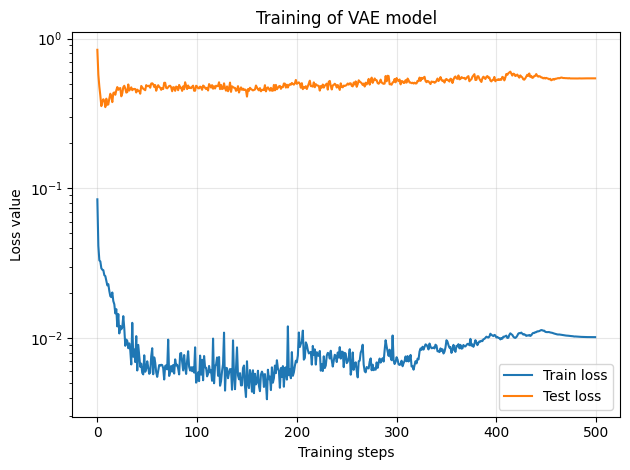

In [19]:
# Plot training loss
x = np.arange(len(loss_arr["test"]))
fig, ax = plt.subplots()
ax.semilogy(x,loss_arr["train"], label="Train loss")
ax.semilogy(x,loss_arr["test"], label="Test loss")
ax.legend()
ax.grid(alpha=0.3)
ax.set_xlabel("Training steps")
ax.set_ylabel("Loss value")
ax.set_title("Training of VAE model")
fig.tight_layout()
plt.show()

In [20]:
# Compute prediction of the trained model
model.eval()
pred = model.predict(X_test)
y_true = Y_test.cpu().numpy()
y_pred = pred.cpu().numpy()

# Compute R² score
r2 = r2_score(y_true, y_pred, multioutput="raw_values")
for col, s in zip(TARGETS, r2):
    print(f"{col:12s} R² = {s:.3f}")
print(f"{'mean':12s} R² = {r2.mean():.3f}")

mean_zeta    R² = 0.742
mean_y       R² = -0.538
mean_z       R² = -0.988
mean_ux      R² = 0.875
mean_uy      R² = -0.485
mean_uz      R² = -0.810
sigma_zeta   R² = 0.828
sigma_y      R² = 0.856
sigma_z      R² = 0.855
sigma_ux     R² = 0.863
sigma_uy     R² = 0.874
sigma_uz     R² = 0.879
q_tot_pC     R² = 0.936
mean         R² = 0.376


In [ ]:
# Load test inputs
test_inputs = pd.read_parquet(f"{PACK}/test_moments_planes.parquet")

# Normalize features with TRAIN-only statistics
test_X = (test_inputs[FEATURES] - mean[FEATURES]) / std[FEATURES]
test_X = torch.tensor(test_X.to_numpy(), dtype=torch.float32, device=device)

# Predict in normalized target space (deterministic mu path)
model.eval()
with torch.no_grad():
    pred_norm = model.predict(test_X).cpu().numpy()

# Denormalize with TRAIN target statistics
pred = pred_norm * std[TARGETS].to_numpy() + mean[TARGETS].to_numpy()
submission = pd.DataFrame(pred, columns=TARGETS)

# Widths and charge can't be negative
sigma_cols = [c for c in TARGETS if c.startswith("sigma_")]
submission[sigma_cols + ["q_tot_pC"]] = submission[sigma_cols + ["q_tot_pC"]].clip(lower=0)

submission.insert(0, "config", test_inputs["config"].to_numpy())
submission.insert(1, "plane_mm", test_inputs["plane_mm"].to_numpy())

assert len(submission) == len(test_inputs)
assert not submission[TARGETS].isna().any().any()

submission.to_csv("submission_campaign_B_moments.csv", index=False)
print(f"submission_campaign_B_moments.csv  ({len(submission):,} rows)")
submission.head()